# Les objectifs de ce TP

1. **Faire une classification binaire** à l’aide de `LogisticRegression` du module `sklearn.linear_model`  
2. **Séparer et normaliser les données**  
3. **Évaluer la qualité du modèle de classification** par des fonctions du module `sklearn.metrics`  
4. **Données non linéairement séparables**  
5. **Données en dimension supérieure à 1**  
6. **Classification multiple** avec `LogisticRegression'

## Q1. Génération de données avec `sklearn.datasets.make_blobs`

Nous utilisons la librairie `sklearn.datasets` pour générer des données simulées sur lesquelles nous appliquons le modèle de classification par **régression logistique**.

Nous utilisons, en particulier, la fonction **`make_blobs`** afin de générer des données pour la classification.

Le code suivant vous permet de générer des **données linéairement séparables** :

In [ ]:
# ============================================
# 1️⃣ Génération des données (à compléter)
# ============================================
from sklearn.datasets import make_blobs

# TODO : générer 1000 points, 2 classes, random_state=3
# x, y = make_blobs( ... )
x, y = make_blobs(n_samples=____ , random_state=____ , centers=____)


# ============================================
# 2️⃣ Affichage d’un résumé du dataset
# ============================================
from collections import Counter

print(x.shape, y.shape)
print(Counter(y))   # Vérifier la répartition des classes


# ============================================
# 3️⃣ Visualisation des données (à compléter)
# ============================================
from matplotlib import pyplot as plt

axes = plt.axes()

# TODO : compléter la commande scatter
# indices des deux premières features
# colorisation selon y
plt.scatter(
    x[:, ____],               # axe X
    x[:, ____],               # axe Y
    c = y.ravel(),            # couleur selon la classe
    s = 50,
    cmap = "RdBu",
    vmin = -0.2,
    vmax = 1.2,
    edgecolor = "white",
    linewidth = 1
)

axes.set(
    aspect = "equal",
    ylim = (-5, 5),
    xlabel = "$X_1$",
    ylabel = "$X_2$"
)

plt.show()


## Q2. Séparation des données en ensembles d'entraînement et de test

---



Séparer les données en deux parties (**training** et **test**) en utilisant la fonction  
**`train_test_split`** du module `sklearn.model_selection`.

In [ ]:
# à completer

# Q3. Normalisation des données avec `sklearn.preprocessing`

Le module `sklearn.preprocessing` contient des fonctions de **normalisation des données**.
On peut effectuer la standardisation par la
fonction StandardScaler et le range scaling par la fonction MinMaxScaler.

In [ ]:
from sklearn import preprocessing
scaler = preprocessing.StandardScaler().fit(x_train)
x_scaled_train =
x_scaled_test =

## Q4. Modèle de régression logistique avec `LogisticRegression`

La méthode de **régression logistique** est implémentée dans le module  
`sklearn.linear_model` sous le nom **`LogisticRegression`**.

In [ ]:
from sklearn.linear_model import LogisticRegression
#à completer

In [ ]:
# ================================================================
# Q5. Critères d’évaluation d’un classifieur
# ================================================================
from sklearn import metrics
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Les prédictions sont supposées définies :
# y_test        = vraies classes
# y_test_pred   = classes prédites
# model         = modèle entraîné
# x_test        = données test


# Formules des métriques d’évaluation (Classification binaire)

---

## Matrice de confusion

|                | Prédit 0 | Prédit 1 |
|----------------|----------|----------|
| **Vrai 0**     | **TN**   | **FP**   |
| **Vrai 1**     | **FN**   | **TP**   |

---

## 1. **Accuracy (Précision globale)**

$$
\boxed{\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}}
$$

---

## 2. **Precision (Précision - classe 1)**

$$
\boxed{\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}}
$$

---

## 3. **Recall / Sensibilité (classe 1)**

$$
\boxed{\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}}
$$

---

## 4. **Specificity (Spécificité - classe 0)**

$$
\boxed{\text{Specificity} = \frac{\text{TN}}{\text{TN} + \text{FP}}}
$$

---

## 5. **F1-Score (classe 1)**

$$
\boxed{\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}}
$$

---

## 6. **AUC (Area Under the ROC Curve)**

$$
\boxed{\text{AUC} = \int_{0}^{1} \text{TPR}(t) \, dt}
$$

---

## 7. **Taux de Vrais Positifs (TPR) et Faux Positifs (FPR)**

$$
\boxed{\text{TPR} = \text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}}
\qquad
\boxed{\text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}}
$$

---

> **Interprétation AUC** :  
> - $ \text{AUC} = 1.0 $ → Parfait  
> - $ \text{AUC} = 0.5 $ → Aléatoire  
> - $ \text{AUC} < 0.5 $ → Pire que le hasard

In [ ]:
# TODO : calculer l’accuracy
accuracy = metrics.accuracy_score(____, ____)
accuracy_percentage = 100 * accuracy
print("Pourcentage des bien classés :", accuracy_percentage)


Classification Report (precision, recall, f1-score)

In [ ]:
print(metrics.classification_report(____, ____))


Matrice de Confusion

In [ ]:
confmat = metrics.confusion_matrix(____, ____)
print("Matrice de confusion :", confmat)

In [ ]:
tn, fp, fn, tp = confusion_matrix(____, ____).ravel()

# Specificity
specificity = tn / (tn + fp)

# TODO : compléter ici
#recall
sensibility =
precision   =

print("Specificity :", specificity)
print("Sensibility :", sensibility)
print("Precision  :", precision)


In [ ]:
probas = model.predict_proba(x_test)
print('auc=', metrics.roc_auc_score(y_test, probas[:,1]))
fpr0, tpr0, _ = metrics.roc_curve(y_test, probas[:, 1])
fig, ax = plt.subplots(1, 1, figsize=(4,4))
ax.plot([0, 1], [0, 1], 'k--')
ax.plot(fpr0, tpr0, label=model.classes_[0])
ax.set_title('Courbe ROC - classifieur')
ax.text(0.5, 0.3, "plus mauvais que\nle hasard dans\ncette zone")
ax.set_xlabel("FPR")
ax.set_ylabel("TPR");
ax.legend();

#**Q5. Logistic Regression from scratch**

## Formules de la Régression Logistique (Implémentation from scratch)

---

### 1. **Fonction sigmoïde**  
Transforme une valeur réelle en probabilité entre 0 et 1.

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

---

### 2. **Fonction de coût (Log-Loss / Binary Cross-Entropy)**  
Mesure l'erreur entre les prédictions et les vraies étiquettes.

$$
J(w, b) = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log(h^{(i)}) + (1 - y^{(i)}) \log(1 - h^{(i)}) \right]
$$

où :  
- $ h^{(i)} = \sigma(z^{(i)}) $  
- $ z^{(i)} = \mathbf{w} \cdot \mathbf{x}^{(i)} + b $

---

### 3. **Calcul du gradient**  
Dérivées partielles pour la descente de gradient.

$$
\frac{\partial J}{\partial w_j} = \frac{1}{m} \sum_{i=1}^{m} (h^{(i)} - y^{(i)}) x_j^{(i)}
\qquad \Rightarrow \quad
\mathbf{dw} = \frac{1}{m} \mathbf{X}^T (\mathbf{h} - \mathbf{y})
$$

$$
\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} (h^{(i)} - y^{(i)})
\qquad \Rightarrow \quad
db = \frac{1}{m} \sum (h - y)
$$

---

### 4. **Mise à jour des paramètres (Descente de gradient)**

$$
\mathbf{w} \leftarrow \mathbf{w} - \alpha \cdot \mathbf{dw}
$$
$$
b \leftarrow b - \alpha \cdot db
$$

où $ \alpha $ = **learning rate**

---

### 5. **Prédiction**

- Probabilité : $ \hat{p} = \sigma(\mathbf{Xw} + b) $  
- Classe prédite :  
$$
\hat{y} =
\begin{cases}
1 & \text{si } \hat{p} \geq 0.5 \\
0 & \text{sinon}
\end{cases}
$$

---

**Note** : Toutes les opérations sont vectorisées avec NumPy pour plus d’efficacité.

In [ ]:
import numpy as np

# --------------------------------
# 1) Fonction sigmoïde
# --------------------------------
def sigmoid(z):
    # TODO: compléter la formule de la sigmoïde
    return  # TODO


# --------------------------------
# 2) Fonction de coût (log-loss)
# --------------------------------
def compute_cost(X, y, w, b):
    m = len(y)

    # TODO: calculer z = Xw + b
    z =  # TODO

    # TODO: calculer h = sigmoid(z)
    h =  # TODO

    # TODO: écrire la formule du coût logistique
    cost =  # TODO

    return cost


# --------------------------------
# 3) Calcul du gradient
# --------------------------------
def compute_gradient(X, y, w, b):
    m = len(y)

    # TODO: z = Xw + b
    z =  # TODO

    # TODO: prédictions h
    h =  # TODO

    # TODO: gradient w
    dw =  # TODO

    # TODO: gradient b
    db =  # TODO

    return dw, db


# --------------------------------
# 4) Entraînement (Gradient Descent)
# --------------------------------
def train_logistic_regression(X, y, lr=0.1, n_iter=1000):
    n_features = X.shape[1]

    # TODO: initialiser w et b
    w =  # TODO
    b =  # TODO

    for i in range(n_iter):

        # TODO: calculer dw, db
        dw, db =  # TODO

        # TODO: mettre à jour w et b
        # w = ...
        # b = ...
        # TODO

        # Afficher le coût toutes les 200 itérations
        if i % 200 == 0:
            cost = compute_cost(X, y, w, b)
            print(f"Iteration {i} | Cost = {cost:.4f}")

    return w, b


# --------------------------------
# 5) Fonction de prédiction
# --------------------------------
def predict(X, w, b):
    # TODO: calculer probas = utiliser fct sigmoid(Xw + b)
    probs =  # TODO

    # TODO: convertir probas en classes 0/1
    return  (probs >= 0.5).astype(int)


In [ ]:
w, b = ...

# --------------------------------------------------
# 4) Prédiction
# --------------------------------------------------
y_pred_test = ...

# --------------------------------------------------
# 5) Évaluation
# --------------------------------------------------
acc = ...
print("Accuracy sur test :", acc)

**Q6. Les données que nous considérons dans cette question sont non linéairement séparable.
Tourner votre code avec ces deux ensembles de données. Qu’est-ce que vous constatez ?
Proposer une solution pour améliorer la qualité de la classification.**

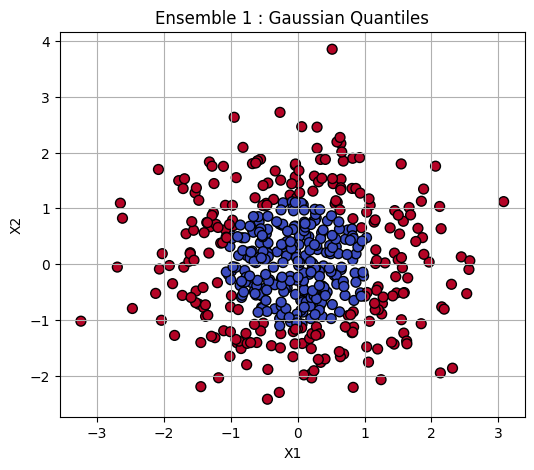

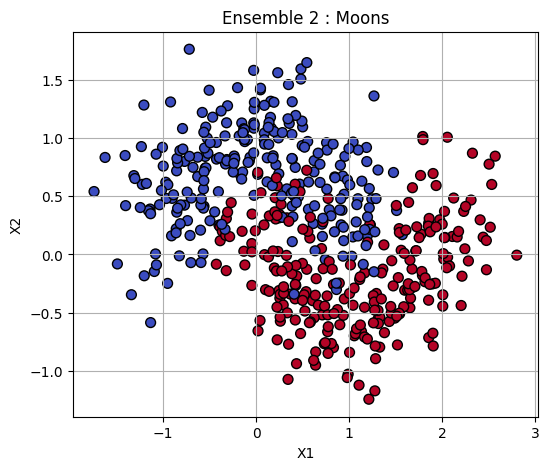

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_gaussian_quantiles, make_moons

# -----------------------------
# Ensemble 1 : Gaussian Quantiles
# -----------------------------
x1, y1 = make_gaussian_quantiles(n_samples=500, n_classes=2, random_state=42)

plt.figure(figsize=(6,5))
plt.scatter(x1[:,0], x1[:,1], c=y1, cmap="coolwarm", edgecolor="k", s=50)
plt.title("Ensemble 1 : Gaussian Quantiles")
plt.xlabel("X1")
plt.ylabel("X2")
plt.grid(True)
plt.show()

# -----------------------------
# Ensemble 2 : Moons
# -----------------------------
x2, y2 = make_moons(n_samples=500, noise=0.3, random_state=42)

plt.figure(figsize=(6,5))
plt.scatter(x2[:,0], x2[:,1], c=y2, cmap="coolwarm", edgecolor="k", s=50)
plt.title("Ensemble 2 : Moons")
plt.xlabel("X1")
plt.ylabel("X2")
plt.grid(True)
plt.show()


**Q7: Utiliser la méthode de régularisation afin d’améliorer votre classification**

In [ ]:
#L2 Regularization, beta=1/C
model = LogisticRegression(penalty='l2', C=10)

**Q8. Nous considérons l’ensemble des données IRIS multiclasses, sur lequel nous appliquons les
deux modèles : LogisticRegression et KNeighborsClassifier. Comparer les
performances de ces deux méthodes.**

In [ ]:
from sklearn.datasets import load_iris
x, y = load_iris( return_X_y=True)
model = LogisticRegression(multi_class='ovr')